In [1]:
import pandas as pd

df = pd.read_csv(
    "../data/processed/willow_and_wick_sales_2025_clean.csv",
    parse_dates=["order_date"],
)

print(df.shape)
df.dtypes

(620, 13)


order_id                    str
order_date       datetime64[us]
customer_id                 str
product                     str
category                    str
quantity                  int64
unit_price              float64
discount_code               str
region                      str
sales_channel               str
is_return                  bool
revenue                 float64
net_revenue             float64
dtype: object

In [2]:
monthly = (
    df.groupby(df["order_date"].dt.to_period("M"))["net_revenue"]
    .sum()
    .round(2)
)

monthly


order_date
2025-01     812.44
2025-02    1267.98
2025-03    1318.74
2025-04    1246.88
2025-05    1558.56
2025-06    1172.46
2025-07     952.28
2025-08    1358.76
2025-09    1288.27
2025-10    3619.42
2025-11    3696.83
2025-12    2840.32
Freq: M, Name: net_revenue, dtype: float64

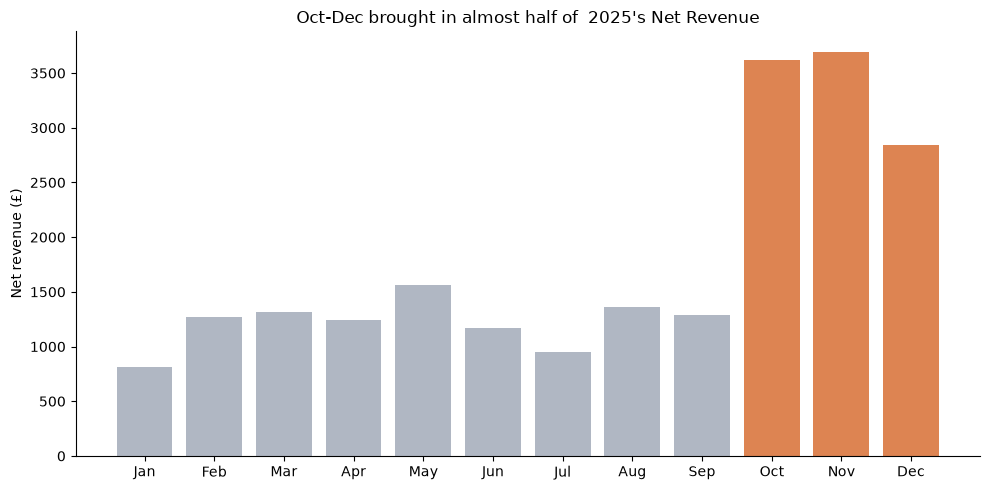

In [7]:
import matplotlib.pyplot as plt

labels = monthly.index.strftime("%b")
colors = ["#DD8452" if m.month>= 10 else "#B0B7C3" for m in monthly.index]

fig, ax = plt.subplots(figsize=(10,5))
ax.bar(labels, monthly.values, color=colors)


ax.set_title("Oct-Dec brought in almost half of  2025's Net Revenue")
ax.set_ylabel("Net revenue (£)")
ax.spines[["top", "right"]].set_visible(False)
plt.xticks(rotation=0)
plt.tight_layout()

from pathlib import Path
Path("../outputs/charts").mkdir(parents=True, exist_ok=True)
fig.savefig("../outputs/charts/01_monthly_revenue.png", dpi=150)
plt.show()